In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import anndata as ad
import scanpy as sc

# scRNAseq
sc_data = sc.read_h5ad('/work/magroup/skrieger/Syndri/data/processed_adata/NSCLC_SC_with_unlabeled.h5ad')
sc_data.obs['batch'] = 'sc'

# spatial transcriptomics
st_data = sc.read_h5ad('/work/magroup/skrieger/Syndri/data/processed_adata/NSCLC_ST.h5ad')
st_data.obs['batch'] = 'st'


# merge st and scRNAseq
adata = sc_data.concatenate(st_data, batch_key='batch', batch_categories=['sc','st'])

# normalize and get PCA
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.scale(adata)
sc.tl.pca(adata, n_comps=50)

# integrate sc and st via harmony
sc.external.pp.harmony_integrate(adata, 'batch', basis='X_pca')

is_st = adata.obs['batch'] == 'st'
is_sc = adata.obs['batch'] == 'sc'

# subset integrated embeddings
sc_data.obsm['X_pca_harmony'] = adata.obsm['X_pca_harmony'][is_sc,:]
st_data.obsm['X_pca_harmony'] = adata.obsm['X_pca_harmony'][is_st,:]



/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/utils.py:

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import anndata as ad
import scanpy as sc
# # manual mapping
# # scRNAseq
# sc_data = sc.read_h5ad('/work/magroup/skrieger/Syndri/data/processed_adata/NSCLC_SC_with_unlabeled.h5ad')

# merge related cell types
sc_data.obs['cell_type_simplified'] = sc_data.obs['Major cell type'].str.replace(r'^b', '', regex=True).str.replace(r'^t', '', regex=True)
sc_data.obs['cell_type_simplified'] = sc_data.obs['cell_type_simplified'].str.replace(r"^Patient\d+.*", "tumor", regex=True)
sc_cts = sorted(list(sc_data.obs['cell_type_simplified'].unique()))
sc_cts

['B cells',
 'Basophils',
 'Ciliated cells',
 'Club cells',
 'Endothelial cells',
 'Fibroblasts',
 'Mast cells',
 'MoMacDC',
 'Monocytes',
 'Myeloid precursor-like',
 'ND',
 'NK cells',
 'Neutrophils',
 'Plasma cells',
 'Platelets',
 'RBC',
 'Smooth muscle cells',
 'T cells',
 'Type I cells',
 'Type II cells',
 'nan',
 'pDC',
 'tumor']

In [20]:
st_data.obs["cell_type"].value_counts()
st_data.obs["cell_type_merged"] = st_data.obs["cell_type"].map({"T CD4 naive": "T CD4+", 
                                                                "T CD4 memory": "T CD4+", 
                                                                "T CD8 naive": "T CD8+", 
                                                                "T CD8 memory": "T CD8+",
                                                                "pDC":"DC",
                                                                "mDC":"DC"}).fillna(st_data.obs["cell_type"])
st_data.obs["cell_type_merged"].value_counts()

cell_type_merged
tumor 9        134099
fibroblast      93413
neutrophil      67726
tumor 6         66805
macrophage      53195
tumor 5         52286
T CD4+          46177
plasmablast     38575
endothelial     38326
DC              30080
B-cell          27512
tumor 13        26757
epithelial      24284
tumor 12        22442
T CD8+          16070
mast            11264
monocyte         8296
NK               7875
Treg             6054
Name: count, dtype: int64

In [21]:
counts = sc_data.obs['cell_type_simplified'].value_counts().reset_index(name='cell_count')

In [39]:
sc_cts
st_cts = ['B-cell','nan','epithelial','epithelial','endothelial','fibroblast','mast','nan','monocyte',
          'nan','nan','NK','neutrophil','plasmablast','nan','nan','nan','nan','epithelial','epithelial','nan','DC','tumor']
counts['ST_cell_type'] = counts['cell_type_simplified'].map(dict(zip(sc_cts,st_cts)))
print(counts[['cell_type_simplified','ST_cell_type','cell_count']].to_string())

      cell_type_simplified ST_cell_type  cell_count
0                      nan          nan      119181
1                  T cells          nan       14729
2              Neutrophils   neutrophil       11639
3                  MoMacDC          nan        9372
4                  B cells       B-cell        5364
5                    tumor        tumor        3694
6                 NK cells           NK        2622
7             Plasma cells  plasmablast        2208
8                Monocytes     monocyte        1434
9               Mast cells         mast         732
10             Fibroblasts   fibroblast         585
11       Endothelial cells  endothelial         535
12           Type II cells   epithelial         403
13                     pDC           DC         354
14     Smooth muscle cells          nan         318
15                     RBC          nan         316
16               Platelets          nan         163
17                      ND          nan          85
18          

In [40]:
sc_data.obs['ST_cell_type'] = sc_data.obs['cell_type_simplified'].map(dict(zip(sc_cts,st_cts)))
sc_data.obs['ST_cell_type'].value_counts()

ST_cell_type
nan            144200
neutrophil      11639
B-cell           5364
tumor            3694
NK               2622
plasmablast      2208
monocyte         1434
mast              732
epithelial        587
fibroblast        585
endothelial       535
DC                354
Name: count, dtype: int64

In [41]:
# Predict T Cell types separately
from sklearn.neighbors import KNeighborsClassifier

tcell_subset = st_data[st_data.obs['cell_type'].str.startswith("T")].obs.index


# ST labels
y_st = st_data[tcell_subset].obs["cell_type_merged"]

# kNN model
knn = KNeighborsClassifier(n_neighbors=30)
knn.fit(st_data[tcell_subset].obsm['X_pca_harmony'], y_st)

# Predict labels for scRNA-seq
sc_tcell_ids = sc_data[sc_data.obs['cell_type_simplified']=='T cells'].obs.index
sc_data.obs.loc[sc_tcell_ids,"ST_cell_type"] = knn.predict(
    sc_data.obsm["X_pca_harmony"][[sc_data.obs.index.get_loc(i) for i in sc_tcell_ids],:]
)


In [42]:
sc_data[sc_data.obs['cell_type_simplified']=='T cells'].obs.groupby('ST_cell_type').size()

ST_cell_type
T CD4+    11125
T CD8+     3551
Treg         53
dtype: int64

In [43]:
sc_data.obs['ST_cell_type'].value_counts()
sc_subset = sc_data[(sc_data.obs['ST_cell_type']!='nan')&(~sc_data.obs['ST_cell_type'].str.startswith('T'))].obs.index


sketch_size = 30000
proportion = sketch_size/ len(st_data)
st_subset = st_data.obs.groupby('cell_type').sample(frac=proportion,replace=False).index


/tmp/ipykernel_3628244/83520165.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  st_subset = st_data.obs.groupby('cell_type').sample(frac=proportion,replace=False).index


In [44]:
# Y Labels
y_labels = pd.concat([sc_data[sc_subset].obs['ST_cell_type'],st_data[st_subset].obs['cell_type_merged']],axis=0)
y_labels.value_counts()

neutrophil     14273
B-cell          6434
tumor 9         5216
fibroblast      4219
plasmablast     3709
tumor           3694
NK              2928
tumor 6         2599
macrophage      2069
tumor 5         2034
endothelial     2026
T CD4+          1796
monocyte        1757
epithelial      1532
DC              1524
mast            1170
tumor 13        1041
tumor 12         873
T CD8+           625
Treg             235
Name: count, dtype: int64

In [45]:
# harmony embeddings
X_train = np.concatenate([sc_data.obsm['X_pca_harmony'][[sc_data.obs.index.get_loc(i) for i in sc_subset],:],
    st_data.obsm['X_pca_harmony'][[st_data.obs.index.get_loc(i) for i in st_subset],:]],axis=0)

In [46]:
# stratified random sampling (maybe just cluster ST and SC separately, and match clusters to clusters)
# train on both ST and manually transferred labels for SC --> predict unlabeled SC labels



#--------------------------------------------------------------------------------------------
# transfer labels
from sklearn.neighbors import KNeighborsClassifier

# kNN model
knn = KNeighborsClassifier(n_neighbors=30)
knn.fit(X_train, y_labels)


sc_unlabeled_ids = sc_data[sc_data.obs['ST_cell_type']=='nan'].obs.index

# Predict labels for scRNA-seq
# knn.predict(
#     sc_data.obsm["X_pca_harmony"][[sc_data.obs.index.get_loc(i) for i in sc_unlabeled_ids]]
# )
sc_data.obs.loc[sc_unlabeled_ids,'ST_cell_type'] = knn.predict(
    sc_data.obsm["X_pca_harmony"][[sc_data.obs.index.get_loc(i) for i in sc_unlabeled_ids]]
)

sc_data.obs['ST_cell_type'].value_counts()

ST_cell_type
plasmablast    75513
neutrophil     30870
B-cell         16716
T CD4+         11972
macrophage      8460
tumor           5622
NK              5055
monocyte        4300
T CD8+          3561
DC              2682
fibroblast      2041
tumor 5         1209
tumor 9         1199
mast            1163
tumor 6         1121
endothelial      977
epithelial       882
tumor 12         411
tumor 13         144
Treg              56
Name: count, dtype: int64

In [47]:
# # merge related cell types
# sc_data.obs['cell_type_simplified'] = sc_data.obs['Major cell type'].str.replace(r'^b', '', regex=True).str.replace(r'^t', '', regex=True)
# sc_data.obs['cell_type_simplified'] = sc_data.obs['cell_type_simplified'].str.replace(r"^Patient\d+.*", "tumor", regex=True)

# merge related cell types
sc_data.obs['predicted_cell_type_simplified'] = sc_data.obs["ST_cell_type"].str.replace(r'^tumor\s+\d+$', 'tumor', regex=True)

In [48]:
import pandas as pd
import numpy as np
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

# ---- set your column names here ----
sc_col = "cell_type_simplified"          # original scRNA-seq type/cluster
st_col = "predicted_cell_type_simplified"   # transferred ST label
# ------------------------------------

obs = sc_data.obs[[st_col, sc_col]].dropna()

# contingency table: rows = ST labels, cols = scRNA cell types
ct = pd.crosstab(obs[st_col], obs[sc_col])

# ct = ct.div(ct.sum(axis=0),axis=1)
# # log2 enrichment analysis
# # ------------------------------------------------------------
# N = ct.values.sum()
# row_tot = ct.sum(axis=1)   # per sc type
# col_tot = ct.sum(axis=0)   # per predicted ST type

# log2_enrich = pd.DataFrame(index=ct.index, columns=ct.columns, dtype=float)

# for sc_type in ct.index:
#     for st_type in ct.columns:
#         a = ct.loc[sc_type, st_type]          # count for this pair

#         # frequencies with small pseudocount to avoid log(0)
#         freq_in_sc = (a + 0.5) / (row_tot[sc_type] + 1.0)
#         freq_global = (col_tot[st_type] + 0.5) / (N + len(col_tot)*0.5)

#         log2_enrich.loc[sc_type, st_type] = np.log2(freq_in_sc / freq_global)


In [49]:
def top_enriched_for_st(st_lab, n=10, q_thresh=0.05):
    df = pd.DataFrame({
        "log2_enrich": log2_enrich.loc[st_lab],
        "qval": qvals.loc[st_lab],
        "count": ct.loc[st_lab]
    }).sort_values("log2_enrich", ascending=False)
    if q_thresh is not None:
        df = df[df["qval"] < q_thresh]
    return df.head(n)

M = ct.fillna(0)

# for each column, get index (0..n_rows-1) of the row with max enrichment
max_row_idx = M.values.argmax(axis=0)   # shape: (n_cols,)

# sort columns so that these indices are monotonically increasing
col_order = np.argsort(max_row_idx)

M_sorted = M.iloc[:, col_order]

In [50]:
sc_data[sc_data.obs['cell_type_simplified']=='Myeloid precursor-like'].obs['predicted_cell_type_simplified'].value_counts()

predicted_cell_type_simplified
neutrophil    11
monocyte       3
Name: count, dtype: int64

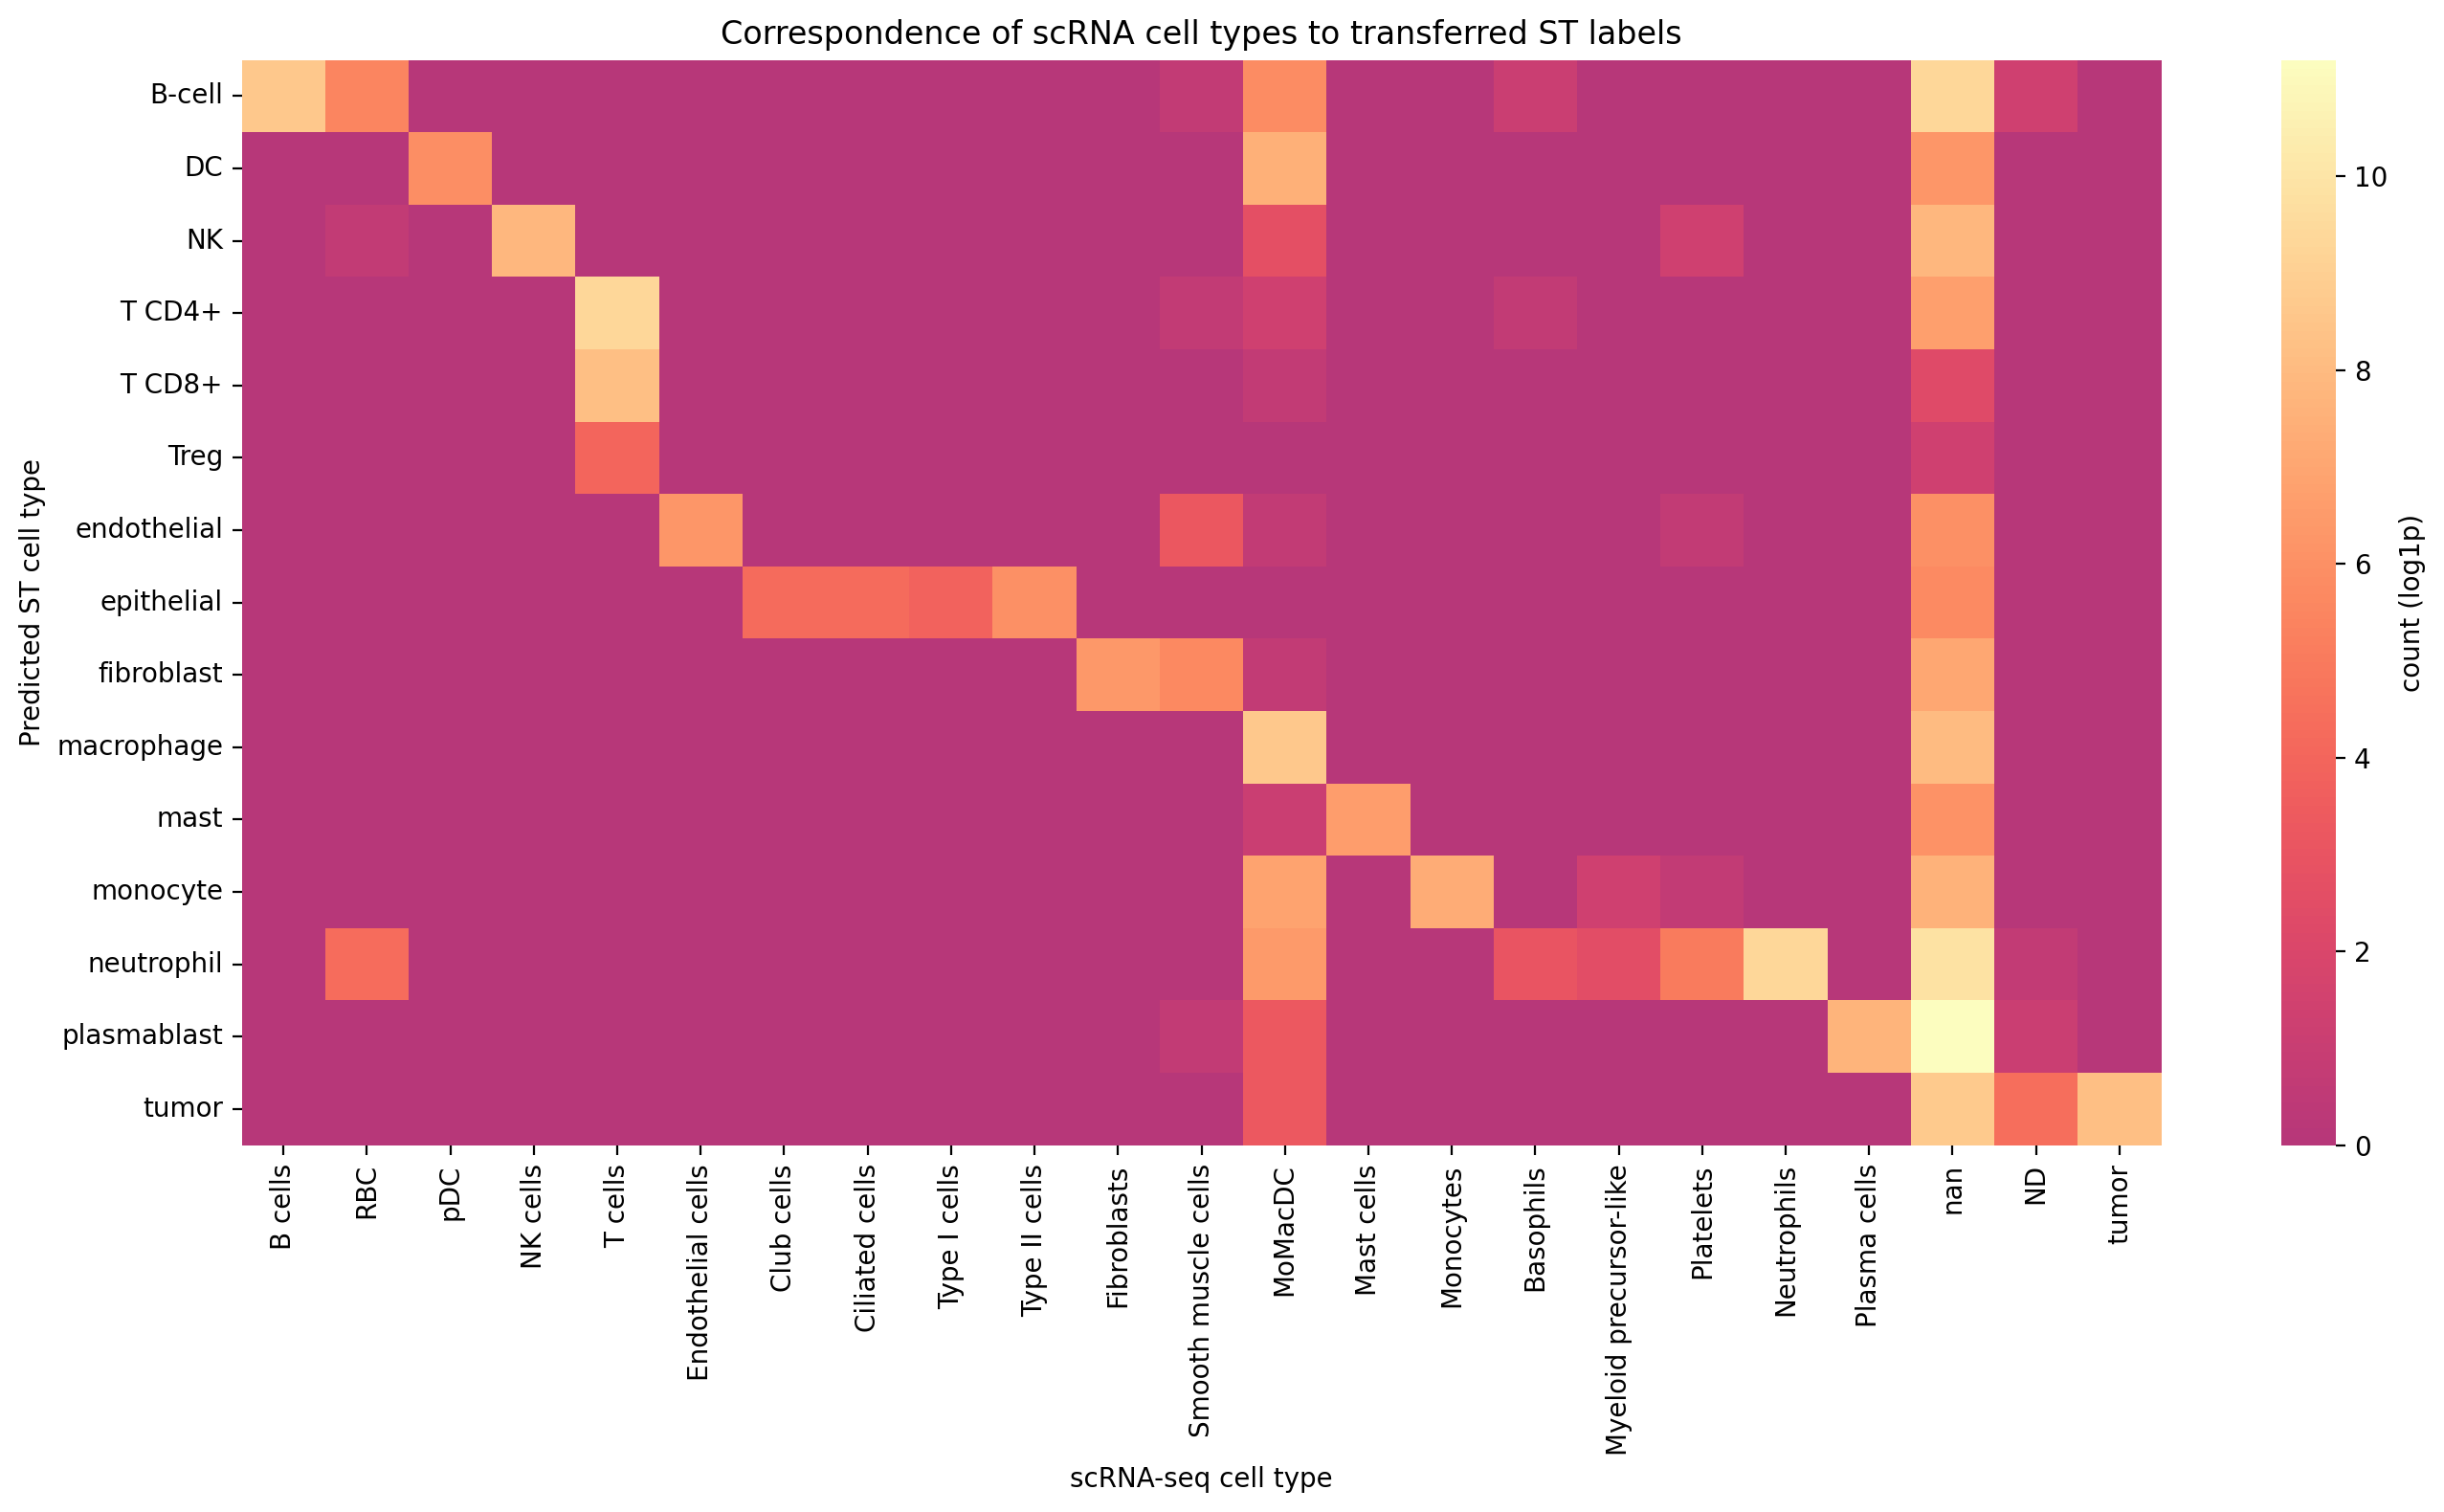

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

fig,ax = plt.subplots(figsize=(14, 8),dpi=200)
sns.heatmap(np.log1p(M_sorted).astype(float),
            cmap="magma", center=0,
            cbar_kws={"label": "count (log1p)"},ax=ax)
ax.set_xlabel('scRNA-seq cell type')
ax.set_ylabel('Predicted ST cell type')
# ax.set_xticklabels(ax.get_xticklabels(),rotation=45)
ax.set_title("Correspondence of scRNA cell types to transferred ST labels")
fig.tight_layout()


In [56]:
sc_data.obs.columns

Index(['species', 'filename', 'sample', 'GSM_ID', 'cell_ID', 'Patient',
       'Tissue', 'Barcoding emulsion', 'Library', 'Total counts',
       'Percent counts from mitochondrial genes', 'Most likely LM22 cell type',
       'Major cell type', 'Minor subset', 'used_in_NSCLC_all_cells',
       'x_NSCLC_all_cells', 'y_NSCLC_all_cells',
       'used_in_NSCLC_and_blood_immune', 'x_NSCLC_and_blood_immune',
       'y_NSCLC_and_blood_immune', 'used_in_NSCLC_immune', 'x_NSCLC_immune',
       'y_NSCLC_immune', 'used_in_NSCLC_non_immune', 'x_NSCLC_non_immune',
       'y_NSCLC_non_immune', 'used_in_blood', 'x_blood', 'y_blood', 'Barcode',
       'batch', 'cell_type_simplified', 'ST_cell_type',
       'predicted_cell_type_simplified'],
      dtype='object')

In [57]:
drop_cols = [c for c in sc_data.obs.columns if c.startswith(("x_",'y_'))]
drop_cols
sc_data.obs = sc_data.obs.drop(columns=drop_cols)
sc_data.obs['cell_type'] = sc_data.obs['predicted_cell_type_simplified']
sc_data.obs = sc_data.obs.drop(columns=['predicted_cell_type_simplified','ST_cell_type','cell_type_simplified'])

sc_data.write_h5ad('/work/magroup/skrieger/Syndri/data/label_transfer/SC_NSCLC_labeltransfer_consolidated.h5ad')

In [59]:
st_data.obs['cell_type'] = st_data.obs['cell_type_merged']
st_data.obs = st_data.obs.drop(columns=['cell_type_merged'])
st_data.write_h5ad('/work/magroup/skrieger/Syndri/data/label_transfer/ST_NSCLC_labeltransfer_consolidated.h5ad')

In [63]:
!pwd
!ls

/home/jwinchel/nsclc_playground


admix_scores.py     GetGeneOverlap.ipynb		  VisualizeImages.ipynb
FormatSCData.ipynb  GSE127465-GPL18573_series_matrix.txt
FormatSTData.ipynb  HarmonyCellTypeMapping.ipynb


In [96]:
from umap import UMAP


umap = UMAP()
subset_size = 30000
proportion = subset_size/len(sc_data)


sc_subset = sc_data.obs.groupby('predicted_cell_type_simplified').sample(frac=proportion).index

proportion = subset_size/len(st_data)
st_subset = st_data.obs.groupby('cell_type').sample(frac=proportion).index

X_train = np.concatenate([sc_data.obsm['X_pca_harmony'][[sc_data.obs.index.get_loc(i) for i in sc_subset],:],
                          st_data.obsm['X_pca_harmony'][[st_data.obs.index.get_loc(i) for i in st_subset],:]],axis=0)

umap = umap.fit(X_train)

/tmp/ipykernel_1866175/2378357231.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  st_subset = st_data.obs.groupby('cell_type').sample(frac=proportion).index
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


In [109]:


st_data.obs[['UMAP_1', 'UMAP_2']] = umap.transform(st_data.obsm["X_pca_harmony"])
sc_data.obs[['UMAP_1', 'UMAP_2']] = umap.transform(sc_data.obsm["X_pca_harmony"])

cell_types = sorted(sc_data.obs['predicted_cell_type_simplified'].unique().tolist())

AttributeError: 'DataFrame' object has no attribute '_sanitize'

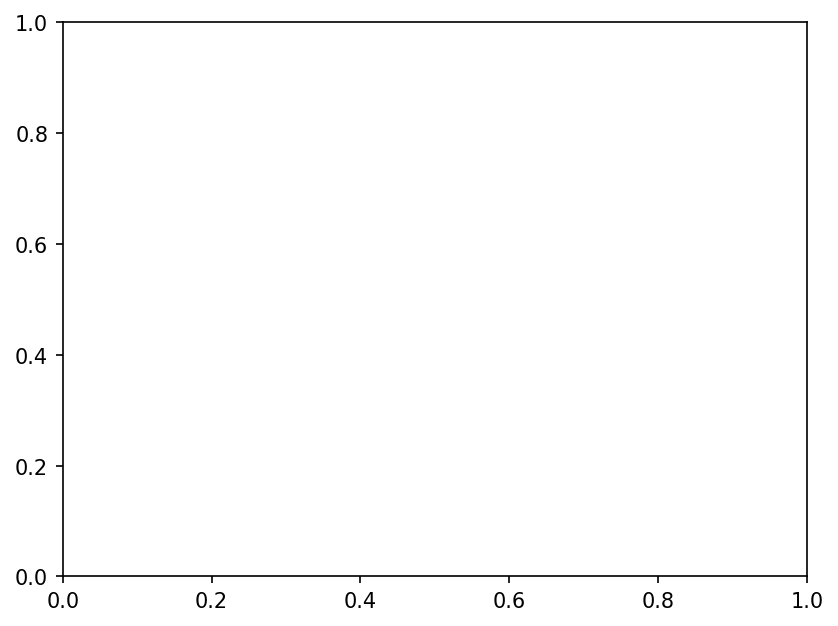

In [ ]:
sc_data.obs['predicted_cell_type_simplified'] = pd.Categorical(sc_data.obs['predicted_cell_type_simplified'],categories=cell_types,ordered=True)
sc_data.obsm['X_umap'] = sc_data.obs[['UMAP_1', 'UMAP_2']].values
fig,ax = plt.subplots(dpi=150)
ax = sc.pl.umap(sc_data.obs[sc_data.obs.index.isin(sc_subset)&(sc_data.obs['predicted_cell_type_simplified']!='')], color='predicted_cell_type_simplified', frameon=True, s=3,ax=ax)
# sns.scatterplot(data=st_data[st_subset].obs, x="UMAP_1", y="UMAP_2", hue="cell_type")

/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


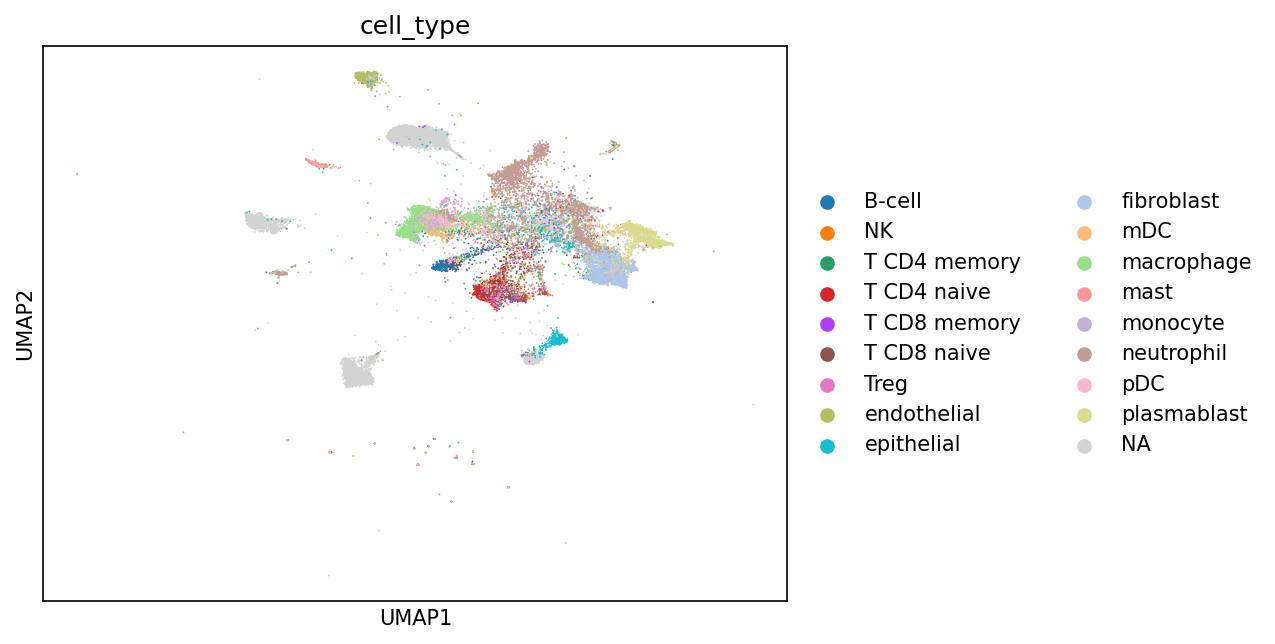

In [107]:
st_data.obs['cell_type'] = pd.Categorical(st_data.obs['cell_type'],categories=cell_types,ordered=True)
st_data.obsm['X_umap'] = st_data.obs[['UMAP_1', 'UMAP_2']].values
fig,ax = plt.subplots(dpi=150)
ax = sc.pl.umap(st_data[st_subset], color='cell_type', frameon=True, s=3,ax=ax)

In [174]:
sc_data.obs['cell_type'] = sc_data.obs['predicted_cell_type_simplified']

adata = sc.concat([sc_data,st_data])

/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/_core/anndata.py:1757: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [177]:
st_data.obs.cell_type.value_counts()



cell_type
fibroblast      93413
neutrophil      67726
macrophage      53195
plasmablast     38575
endothelial     38326
T CD4 naive     29327
B-cell          27512
epithelial      24284
T CD4 memory    16850
mDC             16796
pDC             13284
mast            11264
T CD8 naive     10565
monocyte         8296
NK               7875
Treg             6054
T CD8 memory     5505
tumor               0
Name: count, dtype: int64

/tmp/ipykernel_1866175/1282410183.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  subset_ids = adata.obs.groupby(['batch','cell_type']).sample(frac=0.2).index
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actua

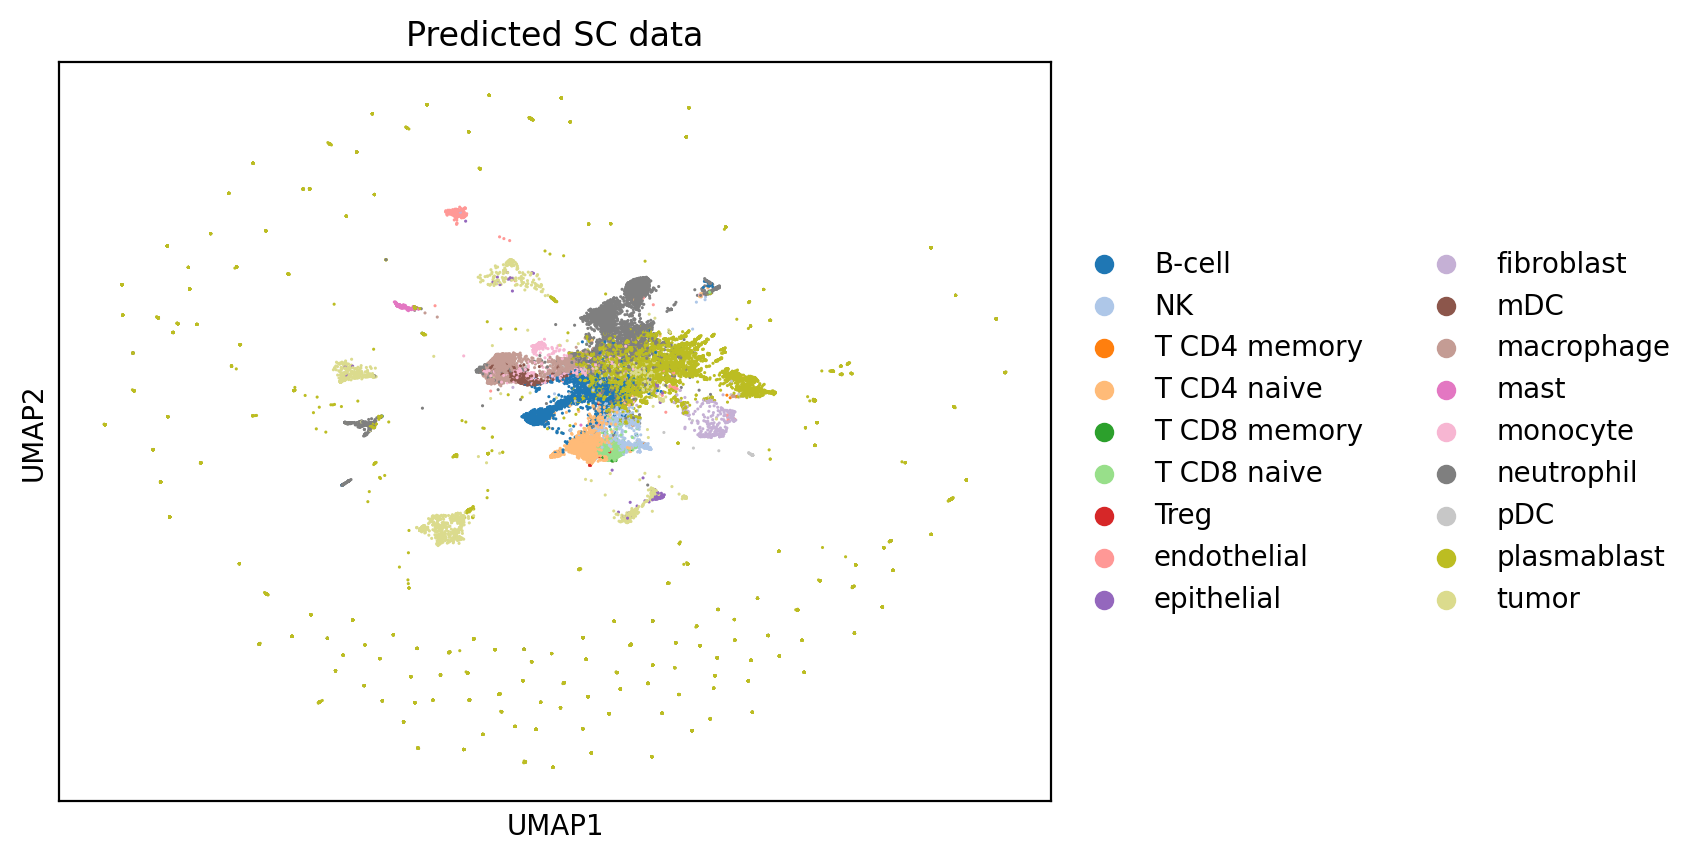

In [173]:
adata.obs = adata.obs.reset_index(drop=True)
cell_types = sorted(adata.obs['cell_type'].unique().tolist())
color_palette = dict(zip(cell_types, plt.get_cmap('tab20').colors[:len(cell_types)]))
adata.obs['cell_type'] = pd.Categorical(adata.obs['cell_type'],categories=cell_types,ordered=True)
subset_ids = adata.obs.groupby(['batch','cell_type']).sample(frac=0.2).index
fig,ax = plt.subplots(dpi=200)
ax = sc.pl.umap(adata[adata.obs.index.isin(subset_ids)&(adata.obs['batch'].isin(['sc']))],color='cell_type',sort_order=cell_types, frameon=True,
                 s=5,ax=ax,palette=color_palette,title="Predicted SC data")
# fig.suptitle("Original ST data")